# Decider graph discovery results

This notebook browses the output of `--method decider-graph-reranked`. It summarizes the final Decider ranking of graph-discovered signals, and draws the search tree for each condition. The tree shows the bounded branches retained by the search; the bold green edge marks Decider’s selected action.

Each probability is conditional on that decision’s menu. Probabilities from different decision steps are not directly comparable. This run discovers signals; it does not by itself establish that the signals are relevant. Use judged or controlled qrels for quality evaluation.


In [9]:
from pathlib import Path
import json
import os
import textwrap

import pandas as pd
import ipywidgets as widgets
from IPython.display import display

MPL_CONFIG = Path('/tmp/simbench-matplotlib')
MPL_CONFIG.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(MPL_CONFIG))
import matplotlib.pyplot as plt

RESULT_FILE = Path('/storage/lcostes/ray-share/experiments/simbench-signals/decider-graph-reranked.jsonl')
if not RESULT_FILE.is_file():
    raise FileNotFoundError(f'Graph-discovery output not found: {RESULT_FILE}')

RECORDS = [json.loads(line) for line in RESULT_FILE.read_text().splitlines() if line.strip()]
RESULTS = {row['condition_id']: row for row in RECORDS}
if not RECORDS or any('graph_search' not in row for row in RECORDS):
    raise ValueError('Expected non-empty Decider graph-discovery JSONL output')
print(f'Loaded {len(RECORDS)} conditions from {RESULT_FILE}')

Loaded 5 conditions from /storage/lcostes/ray-share/experiments/simbench-signals/decider-graph.jsonl


,condition_id,condition,model_calls,signals_returned,stop_reason,decision states with traversal available
0,condition-001,I'm looking for products that serve similar pu...,5,6,model_stopped_search,4
1,condition-002,Which products appeal to similar customers bas...,11,8,model_stopped_search,3
2,condition-003,Show me reviews that provide useful insights i...,7,10,max_signals_reached,4
3,condition-004,Prioritize products that offer a good balance ...,5,7,model_stopped_search,4
4,condition-005,I'd like to discover customers with similar ta...,8,10,max_signals_reached,3


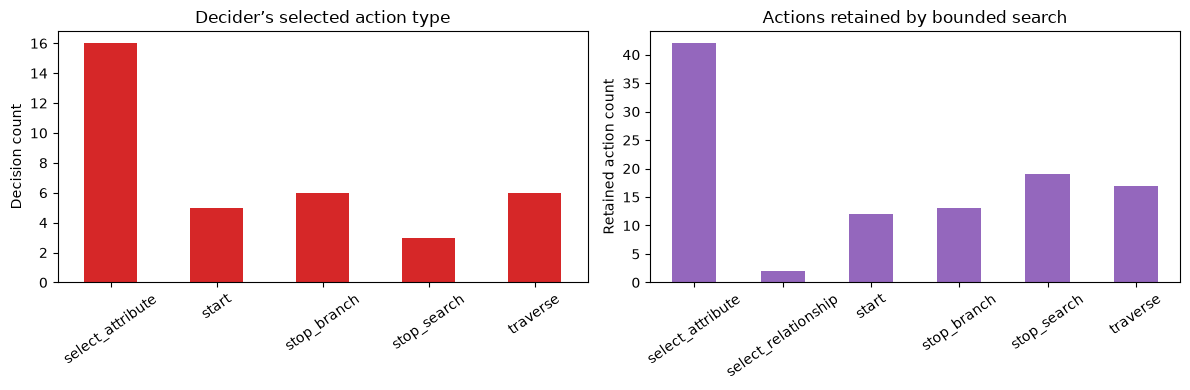

In [10]:
# Run-level overview: search effort, returned signals, and why each search ended.
OVERVIEW = pd.DataFrame([
    {
        'condition_id': row['condition_id'],
        'condition': row['condition'],
        'model_calls': row['graph_search']['model_calls'],
        'signals_returned': len(row['signals']),
        'stop_reason': row['graph_search']['stop_reason'],
        'decision states with traversal available': sum(
            any(a['kind'] == 'traverse' for a in step['legal_actions'])
            for step in row['graph_search']['trace']
        ),
    }
    for row in RECORDS
])
display(OVERVIEW)

choice_rows = []
beam_rows = []
for row in RECORDS:
    for step in row['graph_search']['trace']:
        chosen = next((a for a in step['legal_actions'] if a['option'] == step['model_choice']), None)
        if chosen:
            choice_rows.append({'condition_id': row['condition_id'], 'kind': chosen['kind']})
        beam_rows.extend({'condition_id': row['condition_id'], 'kind': a['kind']} for a in step['expanded_actions'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.Series([r['kind'] for r in choice_rows]).value_counts().sort_index().plot.bar(ax=axes[0], color='#d62728')
axes[0].set_title('Decider’s selected action type')
axes[0].set_ylabel('Decision count')
axes[0].tick_params(axis='x', rotation=35)
pd.Series([r['kind'] for r in beam_rows]).value_counts().sort_index().plot.bar(ax=axes[1], color='#9467bd')
axes[1].set_title('Actions retained by bounded search')
axes[1].set_ylabel('Retained action count')
axes[1].tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()

In [11]:
def show_condition(condition_id):
    row = RESULTS[condition_id]
    print(condition_id + ': ' + row['condition'])
    print(f"Stop: {row['graph_search']['stop_reason']} | model calls: {row['graph_search']['model_calls']} | signals: {len(row['signals'])}")
    signals = pd.DataFrame([
        {
            'kind': signal['kind'],
            'hops': signal['hops'],
            'path': ' → '.join(signal['path']),
            'signal': (signal['attribute_table'] + '.' + signal['attribute_column']) if signal['kind'] == 'attribute' else 'relationship path',
            'description': signal['description'],
        }
        for signal in row['signals']
    ])
    display(signals)
    decisions = []
    for step in row['graph_search']['trace']:
        selected = next((a for a in step['legal_actions'] if a['option'] == step['model_choice']), None)
        decisions.append({
            'step': step['decision_index'],
            'branch': step['branch_id'] if step['branch_id'] is not None else 'root',
            'path': ' → '.join(step['current_path'] or ()),
            'selected action': step['model_choice'],
            'selected probability': None if selected is None else round(selected['probability'], 4),
            'retained options': '; '.join(f"{a['option']} [p={a['probability']:.3f}]" for a in step['expanded_actions']),
        })
    display(pd.DataFrame(decisions))

CONDITION_ID = RECORDS[0]['condition_id']
widgets.interact(show_condition, condition_id=widgets.Dropdown(options=list(RESULTS), value=CONDITION_ID, description='Condition'))

interactive(children=(Dropdown(description='Condition', options=('condition-001', 'condition-002', 'condition-…

<function __main__.show_condition(condition_id)>

In [ ]:
def _branch_history(step):
    prefix = '- Prior decisions on this branch: '
    for line in step['state_context'].splitlines():
        if line.startswith(prefix):
            value = line[len(prefix):]
            return [] if value == 'none' else value.split(' | ')
    return []

def _short_action(action):
    kind = action['kind']
    if kind == 'start':
        detail = action.get('target_table', '')
    elif kind == 'traverse':
        detail = action.get('target_table', '')
    elif action.get('candidate'):
        candidate = action['candidate']
        detail = candidate.get('attribute_table')
        if detail:
            detail += '.' + str(candidate.get('attribute_column'))
        else:
            detail = 'relationship path'
    else:
        detail = 'stop branch' if kind == 'stop_branch' else 'stop search'
    return f"{kind}: {detail} (p={action['probability']:.2f})"

def plot_decision_tree(condition_id, figsize_width=18):
    row = RESULTS[condition_id]
    steps = row['graph_search']['trace']
    root = steps[0]
    by_branch = {step['branch_id']: step for step in steps if step['branch_id'] is not None}
    child_by_parent_action = {}
    for child in steps[1:]:
        history = _branch_history(child)
        if history:
            child_by_parent_action[(child['parent_branch_id'], history[-1])] = child

    # A stop-search choice ends the search immediately; alternatives after it were not expanded.
    def used_actions(step):
        actions = step['expanded_actions']
        chosen = next((a for a in actions if a['option'] == step['model_choice']), None)
        if chosen and chosen['kind'] == 'stop_search':
            return [chosen]
        return [a for a in actions if a['kind'] != 'stop_search']

    nodes = []
    edges = []
    cursor = [0.0]
    seen = set()

    def build(step, depth):
        branch = step['branch_id']
        key = ('decision', branch if branch is not None else 'root')
        if key in seen:
            y = cursor[0]
            cursor[0] += 1
            return {'key': key, 'x': depth, 'y': y, 'children': []}
        seen.add(key)
        node = {'key': key, 'x': depth, 'y': None, 'children': []}
        nodes.append({'key': key, 'x': depth, 'y': None, 'type': 'decision', 'label': f"D{step['decision_index']}"})
        for action in used_actions(step):
            child_step = child_by_parent_action.get((branch, action['option']))
            if child_step is not None:
                child = build(child_step, depth + 1)
            else:
                child = {'key': ('action', len(nodes), len(edges)), 'x': depth + 1, 'y': cursor[0], 'children': []}
                cursor[0] += 1
                suffix = '' if action['kind'] in ('stop_branch', 'stop_search') else ' (state not visited before stopping)'
                nodes.append({'key': child['key'], 'x': child['x'], 'y': child['y'], 'type': action['kind'], 'label': _short_action(action) + suffix})
            node['children'].append((action, child))
            edges.append((node, action, child))
        if node['children']:
            node['y'] = sum(child['y'] for _, child in node['children']) / len(node['children'])
        else:
            node['y'] = cursor[0]
            cursor[0] += 1
        for saved in nodes:
            if saved['key'] == key:
                saved['y'] = node['y']
                break
        return node

    tree = build(root, 0)
    height = max(5, min(30, 0.42 * max(cursor[0], 8)))
    fig, ax = plt.subplots(figsize=(figsize_width, height))
    colors = {'decision': '#e8eef7', 'start': '#cfe8ff', 'traverse': '#cfe8ff', 'select_attribute': '#d9f2d9', 'select_relationship': '#d9f2d9', 'stop_branch': '#eeeeee', 'stop_search': '#ffd9d9'}
    for parent, action, child in edges:
        is_model_choice = action['option'] == parent_step_choice(parent, steps)
        color = '#228833' if is_model_choice else '#777777'
        ax.plot([parent['x'], child['x']], [parent['y'], child['y']], color=color, linewidth=2 if is_model_choice else 1, alpha=0.85, zorder=1)
        mid_x = (parent['x'] + child['x']) / 2
        mid_y = (parent['y'] + child['y']) / 2
        ax.text(mid_x, mid_y, _short_action(action), fontsize=7, ha='left', va='center', color=color, bbox={'facecolor': 'white', 'alpha': 0.78, 'edgecolor': 'none', 'pad': 1}, zorder=3)
    for node in nodes:
        color = colors.get(node['type'], '#eeeeee')
        if node['type'] == 'decision':
            ax.scatter(node['x'], node['y'], s=520, marker='o', facecolor=color, edgecolor='#333333', zorder=2)
            ax.text(node['x'], node['y'], node['label'], ha='center', va='center', fontsize=8, weight='bold', zorder=4)
        else:
            ax.scatter(node['x'], node['y'], s=55, marker='s', facecolor=color, edgecolor='#555555', zorder=2)
            ax.text(node['x'] + 0.08, node['y'], node['label'], ha='left', va='center', fontsize=7, zorder=4)
    ax.set_title(f"{condition_id} — Decider graph-search tree")
    ax.set_xlabel('Decision depth')
    ax.set_yticks([])
    ax.set_xticks(sorted({node['x'] for node in nodes}))
    ax.grid(axis='x', alpha=0.2)
    ax.set_xlim(-0.5, max(node['x'] for node in nodes) + 1.6)
    ax.set_ylim(max(node['y'] for node in nodes) + 1, min(node['y'] for node in nodes) - 1)
    for spine in ('left', 'right', 'top'):
        ax.spines[spine].set_visible(False)
    fig.tight_layout()
    plt.show()

def parent_step_choice(parent, steps):
    branch = parent['key'][1]
    step = next((item for item in steps if item['branch_id'] == (None if branch == 'root' else branch)), None)
    return None if step is None else step['model_choice']

widgets.interact(
    plot_decision_tree,
    condition_id=widgets.Dropdown(options=list(RESULTS), value=CONDITION_ID, description='Tree'),
)

interactive(children=(Dropdown(description='Tree', options=('condition-001', 'condition-002', 'condition-003',…

<function __main__.plot_decision_tree(condition_id, figsize_width=18)>

## Reading the decision tree

Each circle is one Decider call. Its outgoing edges show actions retained by the bounded search; green marks Decider’s top choice for that call, and gray marks additional branches retained by `--branch-width`. Attribute and traversal squares show actions whose resulting state was not reached before the search stopped or exhausted its call budget. Red squares mark stopping the whole search.

The output signal list is the union of signals selected across explored branches. It can therefore contain more signals than the number of model calls. To inspect another condition, change `CONDITION_ID` in the previous code cell and rerun the condition and tree cells.